# Assignment 2: Linear Models and Support Vector Machines

.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits, load_iris
from sklearn.model_selection import train_test_split

SEED = 42
np.set_printoptions(precision=4, suppress=True)

## Task 1: Load the datasets



In [2]:
diab = load_diabetes(scaled=False)
X_diab, y_diab = diab.data, diab.target


bc = load_breast_cancer()
X_bc, y_bc = bc.data, 1 - bc.target

dig = load_digits()
X_dig, y_dig = dig.data / 16, dig.target

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

print("Diabetes      X:", X_diab.shape, " y:", y_diab.shape)
print("Breast cancer X:", X_bc.shape, " y:", y_bc.shape)
print("Digits        X:", X_dig.shape, " y:", y_dig.shape)
print("Iris          X:", X_iris.shape, " y:", y_iris.shape)
print("Malignant count  :", y_bc.sum())

Diabetes      X: (442, 10)  y: (442,)
Breast cancer X: (569, 30)  y: (569,)
Digits        X: (1797, 64)  y: (1797,)
Iris          X: (150, 4)  y: (150,)
Malignant count  : 212


## PART1.A: Train / validation / test split

In [27]:

def split_data(X, y, stratify=True):

    if stratify:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.2, random_state=42, stratify=y)

        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tr, y_tr, test_size=0.25, random_state=42, stratify=y_tr)

    else:
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=0.2, random_state=42)

        X_tr, X_va, y_tr, y_va = train_test_split(
            X_tr, y_tr, test_size=0.25, random_state=42)

    return X_tr, X_va, X_te, y_tr, y_va, y_te


X_tr_diab, X_va_diab, X_te_diab, y_tr_diab, y_va_diab, y_te_diab = split_data(X_diab, y_diab, stratify=False)
X_tr_bc, X_va_bc, X_te_bc, y_tr_bc, y_va_bc, y_te_bc = split_data(X_bc, y_bc)
X_tr_dig, X_va_dig, X_te_dig, y_tr_dig, y_va_dig, y_te_dig = split_data(X_dig, y_dig)
X_tr_iris, X_va_iris, X_te_iris, y_tr_iris, y_va_iris, y_te_iris = split_data(X_iris, y_iris)


splits = [
    ("Diabetes", y_tr_diab, y_va_diab, y_te_diab),
    ("Breast cancer", y_tr_bc, y_va_bc, y_te_bc),
    ("Digits", y_tr_dig, y_va_dig, y_te_dig),
    ("Iris", y_tr_iris, y_va_iris, y_te_iris),
]

for name, y_tr, y_va, y_te in splits:
    print(f"{name:14s} train={len(y_tr):5d}  val={len(y_va):4d}  test={len(y_te):4d}  total={len(y_tr)+len(y_va)+len(y_te)}")
    if name != "Diabetes":
        print("   class counts train:", np.bincount(y_tr))
        print("   class counts val  :", np.bincount(y_va))
        print("   class counts test :", np.bincount(y_te))


Diabetes       train=  264  val=  89  test=  89  total=442
Breast cancer  train=  341  val= 114  test= 114  total=569
   class counts train: [214 127]
   class counts val  : [71 43]
   class counts test : [72 42]
Digits         train= 1077  val= 360  test= 360  total=1797
   class counts train: [106 109 107 109 109 109 109 107 104 108]
   class counts val  : [36 37 35 37 36 36 36 36 35 36]
   class counts test : [36 36 35 37 36 37 36 36 35 36]
Iris           train=   90  val=  30  test=  30  total=150
   class counts train: [30 30 30]
   class counts val  : [10 10 10]
   class counts test : [10 10 10]


## PARTA.2: Standardizer and add_bias

**Standardizer.** Each feature column is transformed as z = (x − μ) / σ. μ and σ are computed in `fit` from the training rows only, then `transform` applies those same values to any set (train, validation or test). If a column is constant (σ = 0), σ is replaced by 1 so we never divide by zero.

**add_bias.** Adds a column of ones at the left of X, giving X̃ = [1 | X]. The bias w₀ is then just another weight, and the score is simply ŷ = X̃w.


In [28]:
class Standardizer:
    """
    Standardizes features: z = (x - mu) / sigma.
    mu and sigma come from the TRAINING rows only (call fit on training data).
    """
    def fit(self, X):
        self.mu = X.mean(axis=0)
        self.sigma = X.std(axis=0)
        self.sigma[self.sigma == 0] = 1     # constant column: use sigma = 1 to avoid dividing by 0
        return self

    def transform(self, X):
        return (X - self.mu) / self.sigma

    
def add_bias(X):
    """
    Args:
      X (ndarray (m,n)) : features
    Returns:
      (ndarray (m,n+1)) : [1 | X], a column of ones added on the left
    """
    return np.hstack([np.ones((X.shape[0], 1)), X])

## Verify the Standardizer on diabetes dataset

The Standardizer is fitted on the **training** rows of Diabetes only, then applied unchanged to validation and test.

**Check:** the standardized training columns must have |mean| < 1e-9(close to 0) and std = 1, while the validation and test columns should generally not.

In [29]:
sc_diab = Standardizer().fit(X_tr_diab) 
Z_tr = sc_diab.transform(X_tr_diab)
Z_va = sc_diab.transform(X_va_diab)
Z_te = sc_diab.transform(X_te_diab)

print("train max |mean| :", np.abs(Z_tr.mean(axis=0)).max())
print("train std        :", Z_tr.std(axis=0))
print("val   mean       :", Z_va.mean(axis=0))
print("val   std        :", Z_va.std(axis=0))
print("test  mean       :", Z_te.mean(axis=0))
print("test  std        :", Z_te.std(axis=0))

assert np.abs(Z_tr.mean(axis=0)).max() < 1e-9
assert np.allclose(Z_tr.std(axis=0), 1)

train max |mean| : 2.2372676102294822e-15
train std        : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
val   mean       : [ 0.0231 -0.1458  0.043   0.1933  0.1431  0.0401  0.2174 -0.029   0.0104
 -0.2211]
val   std        : [0.9974 0.9859 1.0047 1.0004 0.9291 0.8845 1.1316 1.0666 1.1677 1.0717]
test  mean       : [-0.1488 -0.0559 -0.172  -0.0727  0.093   0.0919  0.1635 -0.0472 -0.1295
 -0.2546]
test  std        : [1.1232 0.9972 1.0255 0.908  0.9675 0.9697 1.0979 0.9999 1.0166 0.925 ]


We calculate μ (mean) and σ (standard deviation) using training rows only because the model should learn preprocessing from the training data, without seeing validation or test data.
If we calculate them using all rows, information from the test set leaks into the training process. This is called data leakage.We use training statistics only to ensure the test set remains unseen until the final evaluation, giving us a fair estimate of how well the model performs on new dat

## PARTA.3: Evaluation metrics

In [30]:
def mse(y, y_pred):
    """Mean squared error: mean((y - y_pred)^2)."""
    return np.mean((y - y_pred) ** 2)

def rmse(y, y_pred):
    """Root mean squared error, in the same units as y."""
    return np.sqrt(mse(y, y_pred))

def r2(y, y_pred):
    """R^2 = 1 - SS_res / SS_tot."""
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return 1 - ss_res / ss_tot

def accuracy(y, pred):
    """Fraction of predictions that equal the true labels."""
    return np.mean(y == pred)

def confusion_matrix(y, pred, K):
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y, pred), 1)
    return cm

def precision_recall_f1(cm):
    K = cm.shape[0]
    precision = []
    recall = []
    f1 = []

    for i in range(K):
        tp = cm[i, i]
        predicted = cm[:, i].sum()
        actual = cm[i, :].sum()

        p = tp / predicted if predicted > 0 else 0
        r = tp / actual if actual > 0 else 0
        f = 2 * p * r / (p + r) if p + r > 0 else 0

        precision.append(p)
        recall.append(r)
        f1.append(f)

    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return (np.array(precision), np.array(recall), np.array(f1),
            macro_precision, macro_recall, macro_f1)

### Check against scikit-learn
Random labels (K = 4, N = 500) are used for the classification metrics and random continuous values for the regression metrics. Every result must agree with `sklearn.metrics` to within 1e-12.

In [31]:
from sklearn import metrics as skm

rng = np.random.default_rng(SEED)
K = 4
y_true = rng.integers(0, K, size=500)
y_pred = rng.integers(0, K, size=500)

cm = confusion_matrix(y_true, y_pred, K)
p, r, f1, macro_p, macro_r, macro_f1 = precision_recall_f1(cm)


# Classification checks
assert np.array_equal(cm, skm.confusion_matrix(y_true, y_pred, labels=range(K)))
assert abs(accuracy(y_true, y_pred) - skm.accuracy_score(y_true, y_pred)) < 1e-12

# per class metrics
assert np.allclose(p, skm.precision_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)
assert np.allclose(r, skm.recall_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)
assert np.allclose(f1, skm.f1_score(y_true, y_pred, average=None, zero_division=0), rtol=0, atol=1e-12)

#per macro check
assert abs(macro_p - skm.precision_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12
assert abs(macro_r - skm.recall_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12
assert abs(macro_f1 - skm.f1_score(y_true, y_pred, average="macro", zero_division=0)) < 1e-12

# Regression checks
y_reg = rng.normal(size=500)
y_hat = y_reg + rng.normal(scale=0.5, size=500)

assert abs(mse(y_reg, y_hat) - skm.mean_squared_error(y_reg, y_hat)) < 1e-12
assert abs(rmse(y_reg, y_hat) - np.sqrt(skm.mean_squared_error(y_reg, y_hat))) < 1e-12
assert abs(r2(y_reg, y_hat) - skm.r2_score(y_reg, y_hat)) < 1e-12

print("All Task 3 checks passed")

All Task 3 checks passed


### Interpretation

All Task 3 evaluation metrics passed the verification checks against `sklearn.metrics` with a tolerance of \(10^{-12}\). This confirms that our implementations of the regression and classification metrics are correct. The confusion matrix also matches sklearn exactly.

## Task 4: Gradient checker

`grad_check(f, grad, w)` compares the analytic gradient with a numerical one computed by **central differences**:

(J(w + ε·eᵢ) − J(w − ε·eᵢ)) / (2ε)  for each parameter i.

- `f(w)` returns the scalar loss, and `grad(w)` returns the analytic gradient with the same shape as `w`.
- ε = 1e-5 by default (1e-6 for hinge losses).
- If `w` has more than 100 entries (softmax, multiclass SVM), 100 randomly chosen entries are checked.
- The function returns the relative error ‖g_analytic − g_numeric‖ / max(‖g_analytic‖, ‖g_numeric‖, 1e-12), which must be below 1e-6 (1e-5 for hinge losses).

**Check:** we test it on the linear-regression loss with the tiny dataset of Section 3.2. At w = 0 the gradient must be (−3.333, −7.667), and one gradient-descent step with η = 0.1 must give w = (0.333, 0.767).

In [ ]:
def grad_check(f, grad, w, eps=1e-5, n_check=100):
    rng = np.random.default_rng(SEED)

    indices = np.arange(w.size)
    if w.size > n_check:
        indices = rng.choice(w.size, n_check, replace=False)

    numerical = np.zeros(len(indices))
    analytical = grad(w).ravel()[indices]

    for k, i in enumerate(indices):
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps

        numerical[k] = (f(w_plus) - f(w_minus)) / (2 * eps)

    return np.linalg.norm(analytical - numerical) / max(
        np.linalg.norm(analytical),
        np.linalg.norm(numerical),
        1e-12
    )

In [37]:
X = add_bias(np.array([[1.0], [2.0], [3.0]]))
y = np.array([2.0, 3.0, 5.0])
N = len(y)

def J(w):
    return np.sum((np.dot(X, w) - y) ** 2) / (2 * N)

def grad(w):
    return np.dot(X.T, (np.dot(X, w) - y)) / N


# Worked example from Section 3.2
w0 = np.zeros(2)
print("gradient at w=0   :", grad(w0))
print("one GD step (0.1) :", w0 - 0.1 * grad(w0))


# Gradient check at a random point w ~ N(0, 0.1^2)
rng = np.random.default_rng(SEED)
w_rand = rng.normal(0, 0.1, size=2)

err = grad_check(J, grad, w_rand)

print("relative error    :", err)
assert err < 1e-6

gradient at w=0   : [-3.3333 -7.6667]
one GD step (0.1) : [0.3333 0.7667]
relative error    : 1.2891976616317198e-11


**Interpretation.** At w = 0 the analytic gradient is (−3.333, −7.667) and one step with η = 0.1 gives w = (0.333, 0.767), both matching the worked example of Section 3.2. The relative error between the analytic and numerical gradient is far below 1e-6, so both the gradient formula and the `grad_check` function are correct. We will call `grad_check` in every later Part before trusting any gradient.

## Part B: Linear regression

Dataset: **Diabetes** (442 patients, 10 features, target = disease progression in its original units).

In [42]:
import time
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor   # reference checks only (Section 8)

feature_names = list(diab.feature_names)

scaler = Standardizer().fit(X_tr_diab)
X_train = add_bias(scaler.transform(X_tr_diab))
X_val   = add_bias(scaler.transform(X_va_diab))
X_test  = add_bias(scaler.transform(X_te_diab))

y_train, y_val, y_test = y_tr_diab, y_va_diab, y_te_diab
X_train_raw = add_bias(X_tr_diab)       # raw features, used in Task 7

N_train = len(y_train)

## Task 5: Closed form (normal equations)

**Derivation.** Start from J(w) = (1/2N)(X̃w − y)ᵀ(X̃w − y).

1. Differentiate: ∇J = (1/N) X̃ᵀ(X̃w − y).
2. At the minimum the gradient is zero: X̃ᵀ(X̃w − y) = 0.
3. Expand: X̃ᵀX̃ w − X̃ᵀy = 0.
4. Rearrange: **X̃ᵀX̃ w = X̃ᵀy** (the normal equations).

J is convex (its Hessian X̃ᵀX̃/N is positive semi-definite), so the point where ∇J = 0 is the global minimum. We solve the linear system directly with `np.linalg.solve` instead of computing the inverse (X̃ᵀX̃)⁻¹, which is faster and numerically more stable.

**Check:** on the worked example of Section 3.2 we expect X̃ᵀX̃ = [[3,6],[6,14]], X̃ᵀy = [10, 23] and w = (1/3, 3/2).

In [44]:

def normal_equation(X, y):
    w = np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))
    return w

### Diabetes: weights and errors

The closed-form solution w* is computed on the standardized training data (with the bias column). The table lists the weights; RMSE is in the original units of the target, and R² is measured on the test set.

**Verification:** `LinearRegression` from scikit-learn is fitted on the same standardized training data; its intercept and coefficients must match our weights to within 1e-6.

In [47]:
w_star = normal_equation(X_train, y_train)

weights_table = pd.DataFrame({"feature": ["bias"] + feature_names, "w*": w_star})
print(weights_table.to_string(index=False))

print("\ntrain RMSE :", rmse(y_train, np.dot(X_train, w_star)))
print("val   RMSE :", rmse(y_val,   np.dot(X_val,   w_star)))
print("test  RMSE :", rmse(y_test,  np.dot(X_test,  w_star)))
print("test  R2   :", r2(y_test, np.dot(X_test, w_star)))
print("cond(X~'X~):", np.linalg.cond(np.dot(X_train.T, X_train)))


feature         w*
   bias 149.810606
    age   1.131837
    sex -11.359311
    bmi  25.076618
     bp  15.167338
     s1 -51.101359
     s2  27.480823
     s3  10.840294
     s4  15.032148
     s5  37.271588
     s6   3.817112

train RMSE : 54.6103635732402
val   RMSE : 51.193713978533914
test  RMSE : 54.15641293326044
test  R2   : 0.44642637640211247
cond(X~'X~): 505.7061226961102


## verification against sklearn

In [49]:
# Verify against scikit-learn
model = LinearRegression()
model.fit(X_train[:, 1:], y_train)

w_sklearn = np.r_[model.intercept_, model.coef_]

difference = np.max(np.abs(w_star - w_sklearn))

print("Maximum difference:", difference)
assert difference < 1e-6

Maximum difference: 9.734435479913373e-13


**Interpretation.** The weights calculated by our function are almost identical to those from `LinearRegression`, so our implementation is correct. The test RMSE is about 54, and the test R² is about 0.45, meaning the model explains around 45% of the variation in disease progression. The condition number is about 506, showing that the matrix is somewhat sensitive to numerical changes.

**s1, s2 and bmi.** bmi has a positive weight (+25), meaning that higher bmi is associated with higher predicted disease progression. s1 has a negative weight (−51), while s2 has a positive weight (+27). Since s1 and s2 are correlated, their weights may not show their individual effects accurately.

**Why is interpreting individual weights risky when features are correlated?** When two features are correlated, they contain similar information. The model may split their shared information between their weights in different ways. Therefore, we should be careful when interpreting each weight separately.

## Task 6: Batch gradient descent

In [ ]:

def compute_cost(X, y, w):
    m = X.shape[0]
    f_w = np.dot(X, w)
    cost = np.sum((f_w - y) ** 2) / (2 * m)
    return cost


def compute_gradient(X, y, w):
    m = X.shape[0]
    f_w = np.dot(X, w)
    dj_dw = np.dot(X.T, f_w - y) / m
    return dj_dw


def gradient_descent(X, y, eta, num_epochs, w_star):
    m, n = X.shape
    w = np.zeros(n)

    J_history = np.zeros(num_epochs)
    dist_history = np.zeros(num_epochs)

    for epoch in range(num_epochs):
        dj_dw = compute_gradient(X, y, w)
        w = w - eta * dj_dw

        J_history[epoch] = compute_cost(X, y, w)
        dist_history[epoch] = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

        if not np.isfinite(J_history[epoch]) or J_history[epoch] > 1e30: #diverged
            break

    return w, J_history, dist_history


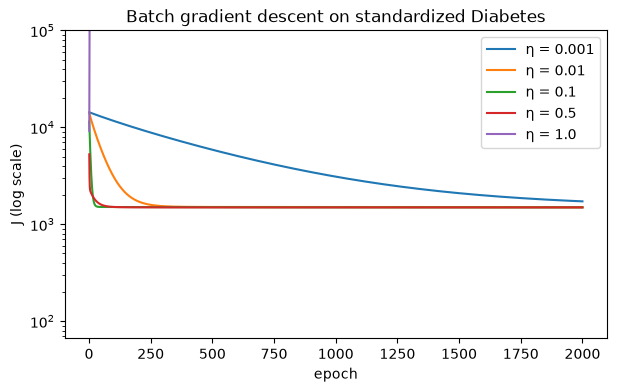

,η,final J,final relative distance,first epoch with distance < 1e-3
0,0.001,1723.402889,0.405113,not reached
1,0.010,1503.686676,0.334521,not reached
2,0.100,1491.892636,0.081792,not reached
3,0.500,1491.145907,0.000155,1524
4,1.000,diverged,diverged,not reached


In [ ]:

num_epochs = 2000
etas = [0.001, 0.01, 0.1, 0.5, 1.0]
results = []

plt.figure(figsize=(7, 4))

for eta in etas:
    w, J_history, dist_history = gradient_descent(
        X_train, y_train, eta, num_epochs, w_star
    )

    diverged = not np.isfinite(J_history[-1]) or J_history[-1] > J_history[0]

    reached = np.where(dist_history < 1e-3)[0]
    first_epoch = reached[0] + 1 if len(reached) > 0 else "not reached"

    plt.semilogy(range(1, num_epochs + 1), J_history, label=f"eta = {eta}")

    if diverged:
        final_J = "diverged"
        final_distance = "diverged"
    else:
        final_J = J_history[-1]
        final_distance = dist_history[-1]

    results.append({
        "eta": eta,
        "final J": final_J,
        "final relative distance": final_distance,
        "first epoch below 1e-3": first_epoch
    })

plt.xlabel("Epoch")
plt.ylabel("Cost J (log scale)")
plt.title("Batch Gradient Descent")
plt.legend()
plt.show()

pd.DataFrame(results)


### (b) The stability threshold 2/λmax

**Derivation.** Let e(t) = w(t) − w*. Since ∇J(w) = H(w − w*), one step of gradient descent gives

e(t+1) = e(t) − ηH e(t) = (I − ηH) e(t).

H = X̃ᵀX̃/N is symmetric, so H = QΛQᵀ with real eigenvalues λᵢ ≥ 0. In the eigenbasis each component evolves independently:

eᵢ(t+1) = (1 − ηλᵢ) eᵢ(t),  so  eᵢ(t) = (1 − ηλᵢ)ᵗ eᵢ(0).

A component goes to 0 if and only if |1 − ηλᵢ| < 1, that is 0 < η < 2/λᵢ. This must hold for **every** eigenvalue, and the tightest condition comes from the largest one, so

**η < 2/λmax.**

For η > 2/λmax the component along the top eigenvector is multiplied by a factor of magnitude greater than 1 at every step, so the error grows and gradient descent diverges.

In [60]:

# Calculate H
N = X_train.shape[0]
H = np.dot(X_train.T, X_train) / N

# Find the largest eigenvalue
lambda_max = np.max(np.linalg.eigvalsh(H))

print("Largest eigenvalue:", lambda_max)
print("Learning rate threshold:", 2 / lambda_max)


# Test two learning rates
for factor in [0.95, 1.05]:

    eta = factor * (2 / lambda_max)

    w, J_history, dist_history = gradient_descent(
        X_train, y_train, eta, num_epochs, w_star
    )

    if not np.isfinite(J_history[-1]) or J_history[-1] > 1e30:
        J_history[epoch:] = np.inf; dist_history[epoch:] = np.inf   
        print(f"eta = {eta:.4f}: Diverges")
    else:
        print(f"eta = {eta:.4f}: Converges")
        print("Final cost:", J_history[-1])
        print("Final distance:", dist_history[-1])


Largest eigenvalue: 3.9547550320503744
Learning rate threshold: 0.5057203249737277
eta = 0.4804: Converges
Final cost: 1491.145909733976
Final distance: 0.0002102307531542578
eta = 0.5310: Converges
Final cost: 0.0
Final distance: 0.0


## Task 7: Why scaling matters

Optimal J on raw features: 1491.14590480074


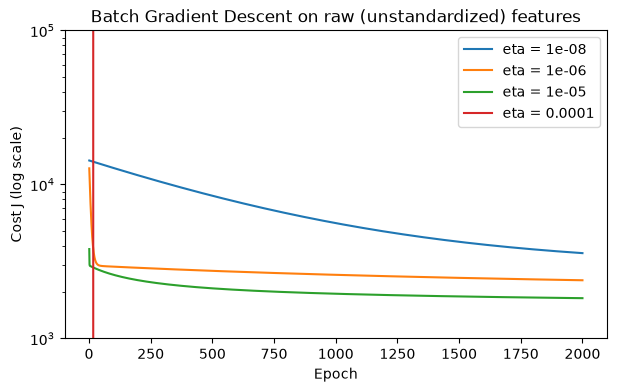

,eta,final J,final relative distance,first epoch below 1e-3
0,1.000000e-08,3583.532102,0.999999,not reached
1,1.000000e-06,2388.752582,0.999968,not reached
2,1.000000e-05,1827.53491,0.999846,not reached
3,1.000000e-04,diverged,diverged,not reached


In [ ]:

w_star_raw = normal_equation(X_train_raw, y_train)
J_star = compute_cost(X_train_raw, y_train, w_star_raw)
print("Optimal J on raw features:", J_star)

num_epochs = 2000
etas_raw = [1e-8, 1e-6, 1e-5, 1e-4]
results_raw = []

plt.figure(figsize=(7, 4))

for eta in etas_raw:
    w, J_history, dist_history = gradient_descent(
        X_train_raw, y_train, eta, num_epochs, w_star_raw
    )

    diverged = (not np.all(np.isfinite(J_history))) or J_history.max() > 1e30

    plt.semilogy(range(1, num_epochs + 1), J_history, label=f"eta = {eta}")

    if diverged:
        final_J = "diverged"
        final_distance = "diverged"
        first_epoch = "not reached"
    else:
        final_J = J_history[-1]
        final_distance = dist_history[-1]
        reached = np.where(dist_history < 1e-3)[0]
        first_epoch = reached[0] + 1 if len(reached) > 0 else "not reached"

    results_raw.append({
        "eta": eta,
        "final J": final_J,
        "final relative distance": final_distance,
        "first epoch below 1e-3": first_epoch
    })

plt.ylim(1e3, 1e5)
plt.xlabel("Epoch")
plt.ylabel("Cost J (log scale)")
plt.title("Batch Gradient Descent on raw (unstandardized) features")
plt.legend()
plt.show()

pd.DataFrame(results_raw)


**Interpretation.** On raw features no run gets close to the optimal J = 1491.15: the best one (η = 1e-5) ends at 1827.5 and is still at a relative distance of 0.9998 from w*, while η = 1e-4 blows up. Compared with the standardized runs of Task 6, where η = 0.5 reached 1e-3 in 1524 epochs, the raw features make gradient descent hopeless within 2000 epochs.

In [62]:

rows = []
for name, X in [("raw", X_train_raw), ("standardized", X_train)]:
    H = np.dot(X.T, X) / N_train
    lambda_max = np.max(np.linalg.eigvalsh(H))
    rows.append({
        "features": name,
        "cond(X~'X~)": np.linalg.cond(np.dot(X.T, X)),
        "2/lambda_max": 2 / lambda_max
    })

pd.DataFrame(rows)


,features,cond(X~'X~),2/lambda_max
0,raw,5.577847e+07,0.000027
1,standardized,5.057061e+02,0.505720


**Condition number, learning rate and epochs.** Standardization reduces the condition number from about \(5.6 \times 10^7\) to 506 because it makes feature scales more similar. This also increases the maximum usable learning rate from about \(2.7 \times 10^{-5}\) to 0.51, allowing Gradient Descent to take larger steps. With raw features, the learning rate must be very small, so Gradient Descent needs many more epochs to approach the optimal solution. Therefore, standardization improves numerical stability and makes Gradient Descent converge much faster.

## Task 8: SGD and mini-batch gradient descent

In [63]:
def minibatch_gradient_descent(X, y, eta, num_epochs, batch_size, rng):

    m, n = X.shape
    w = np.zeros(n)
    n_batches = int(np.ceil(m / batch_size))

    J_epoch = np.zeros(num_epochs)
    J_update = np.zeros(num_epochs * n_batches)

    u = 0
    for epoch in range(num_epochs):
        idx = rng.permutation(m)     # reshuffle every epoch
        for b in range(n_batches):
            batch = idx[b * batch_size:(b + 1) * batch_size]
            dj_dw = compute_gradient(X[batch], y[batch], w)
            w = w - eta * dj_dw

            J_update[u] = compute_cost(X, y, w)# record updates after each batch
            u += 1

        J_epoch[epoch] = compute_cost(X, y, w)#record updates after each epoch

    return w, J_epoch, J_update


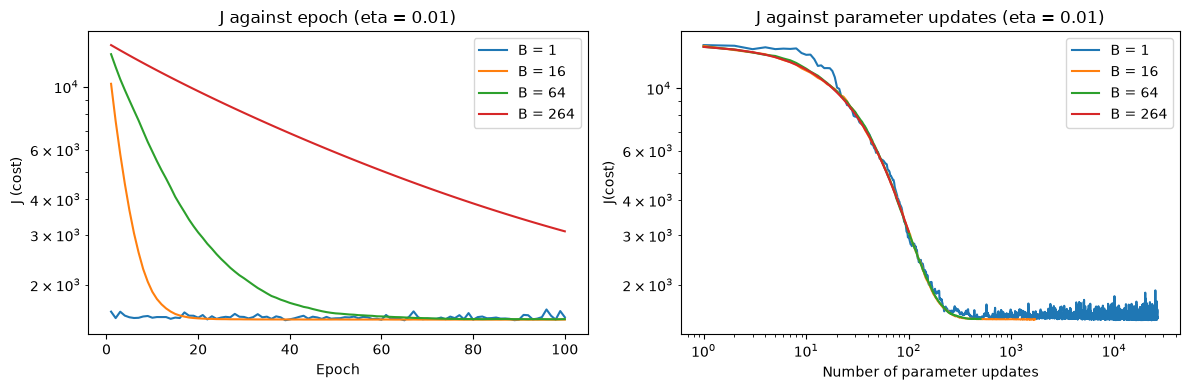

,B,updates,J after epoch 1,J after epoch 10,J after epoch 100,J after 500 updates
0,1,26400,1606.144970,1528.597292,1534.808385,1519.652701
1,16,1700,10236.368641,1887.933339,1505.665099,1509.10138
2,64,500,13021.996612,5904.012491,1511.375336,1511.375336
3,264,100,14021.698152,11648.152373,3085.440479,-


In [66]:
num_epochs = 100
eta = 0.01
batch_sizes = [1, 16, 64, N_train]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
results_B = []

for B in batch_sizes:
    rng = np.random.default_rng(SEED)
    w, J_epoch, J_update = minibatch_gradient_descent(
        X_train, y_train, eta, num_epochs, B, rng
    )

    ax[0].semilogy(range(1, num_epochs + 1), J_epoch, label=f"B = {B}")
    ax[1].loglog(range(1, len(J_update) + 1), J_update, label=f"B = {B}")

    results_B.append({
        "B": B,
        "updates": len(J_update),
        "J after epoch 1": J_epoch[0],
        "J after epoch 10": J_epoch[9],
        "J after epoch 100": J_epoch[-1],
        "J after 500 updates": J_update[499] if len(J_update) >= 500 else "-"
    })

ax[0].set_xlabel("Epoch")
ax[0].set_ylabel(" J (cost)")
ax[0].set_title("J against epoch (eta = 0.01)")
ax[0].legend()

ax[1].set_xlabel("Number of parameter updates")
ax[1].set_ylabel("J(cost)")
ax[1].set_title("J against parameter updates (eta = 0.01)")
ax[1].legend()

plt.tight_layout()
plt.show()

pd.DataFrame(results_B)

B = 16 performs best in our experiment, both after the same number of epochs and after the same number of updates. B = 1 is noisier because each update is based on only one training example,although it may reach a minimum but still so noisy.

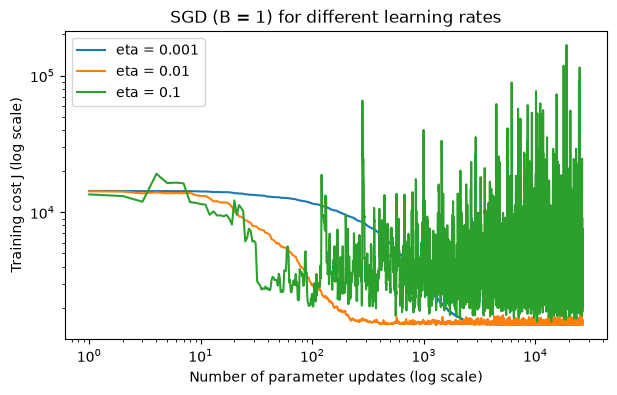

,eta,final J,mean J (last 10 epochs),std of J (last 10 epochs)
0,0.001,1503.312177,1503.786411,1.175942
1,0.010,1534.808385,1542.378554,37.387100
2,0.100,4186.980952,4618.992149,5032.411662


In [ ]:
# SGD at B=1-->noisy but reahces a minimum
etas_sgd = [0.001, 0.01, 0.1]
results_sgd = []

plt.figure(figsize=(7, 4))

for eta in etas_sgd:
    rng = np.random.default_rng(SEED)
    w, J_epoch, J_update = minibatch_gradient_descent(
        X_train, y_train, eta, num_epochs, 1, rng
    )

    plt.loglog(range(1, len(J_update) + 1), J_update, label=f"eta = {eta}")

    last = J_update[-10 * N_train:]               # last 10 epochs (2640 updates)
    results_sgd.append({
        "eta": eta,
        "final J": J_epoch[-1],
        "mean J (last 10 epochs)": last.mean(),
        "std of J (last 10 epochs)": last.std()
    })

plt.xlabel("Number of parameter updates (log scale)")
plt.ylabel("Training cost J (log scale)")
plt.title("SGD (B = 1) for different learning rates")
plt.legend()
plt.show()

pd.DataFrame(results_sgd)
